In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data/SMRT_dataset.csv', sep=';')

print("Shape:", df.shape)
print("\nFirst 3 rows:")
print(df.head(3))
print("\nAll column names:")
print(df.columns.tolist())

Shape: (80038, 3)

First 3 rows:
   pubchem     rt                                              inchi
0     5139   93.5    InChI=1S/C3H8N2S/c1-2-6-3(4)5/h2H2,1H3,(H3,4,5)
1     3505  687.8  InChI=1S/C19H25Cl2N3O3/c1-27-19(26)23-8-9-24(1...
2     2159  590.7  InChI=1S/C17H27N3O4S/c1-4-20-8-6-7-12(20)11-19...

All column names:
['pubchem', 'rt', 'inchi']


In [7]:
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors
from rdkit.Chem.inchi import MolFromInchi

# Test on one molecule first
sample_inchi = df['inchi'].iloc[0]
mol = MolFromInchi(sample_inchi)

if mol:
    print("Molecule loaded successfully")
    print("Molecular Weight:", Descriptors.MolWt(mol))
    print("LogP:", Descriptors.MolLogP(mol))
    print("H-Bond Donors:", rdMolDescriptors.CalcNumHBD(mol))
    print("H-Bond Acceptors:", rdMolDescriptors.CalcNumHBA(mol))
    print("TPSA:", Descriptors.TPSA(mol))
    print("Rotatable Bonds:", rdMolDescriptors.CalcNumRotatableBonds(mol))
    print("Heavy Atom Count:", mol.GetNumHeavyAtoms())
else:
    print("Failed to parse molecule")

Molecule loaded successfully
Molecular Weight: 104.178
LogP: 0.63297
H-Bond Donors: 2
H-Bond Acceptors: 2
TPSA: 49.870000000000005
Rotatable Bonds: 1
Heavy Atom Count: 6


In [9]:
# Read first 5 lines raw to see what it looks like
with open('data/SMRT_dataset.csv', 'r') as f:
    for i, line in enumerate(f):
        print(repr(line))
        if i == 4:
            break

'"pubchem";"rt";"inchi"\n'
'5139;93.5;"InChI=1S/C3H8N2S/c1-2-6-3(4)5/h2H2,1H3,(H3,4,5)"\n'
'3505;687.8;"InChI=1S/C19H25Cl2N3O3/c1-27-19(26)23-8-9-24(15(13-23)12-22-6-2-3-7-22)18(25)11-14-4-5-16(20)17(21)10-14/h4-5,10,15H,2-3,6-9,11-13H2,1H3/t15-/m1/s1"\n'
'2159;590.7;"InChI=1S/C17H27N3O4S/c1-4-20-8-6-7-12(20)11-19-17(21)13-9-16(25(22,23)5-2)14(18)10-15(13)24-3/h9-10,12H,4-8,11,18H2,1-3H3,(H,19,21)/t12-/m1/s1"\n'
'1340;583.6;"InChI=1S/C9H7NO2/c11-8-3-1-2-7-6(8)4-5-10-9(7)12/h1-5,11H,(H,10,12)"\n'


In [10]:
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors
from rdkit.Chem.inchi import MolFromInchi

def compute_features(inchi):
    try:
        mol = MolFromInchi(inchi)
        if mol is None:
            return None
        return {
            'mol_weight':       Descriptors.MolWt(mol),
            'logp':             Descriptors.MolLogP(mol),
            'hbd':              rdMolDescriptors.CalcNumHBD(mol),
            'hba':              rdMolDescriptors.CalcNumHBA(mol),
            'tpsa':             Descriptors.TPSA(mol),
            'rotatable_bonds':  rdMolDescriptors.CalcNumRotatableBonds(mol),
            'heavy_atom_count': mol.GetNumHeavyAtoms(),
            'ring_count':       rdMolDescriptors.CalcNumRings(mol),
            'aromatic_rings':   rdMolDescriptors.CalcNumAromaticRings(mol),
        }
    except:
        return None

print("Computing features for all molecules... please wait")

features_list = []
failed = 0

for i, row in df.iterrows():
    feats = compute_features(row['inchi'])
    if feats:
        feats['pubchem'] = row['pubchem']
        feats['rt']      = row['rt']
        features_list.append(feats)
    else:
        failed += 1

df_features = pd.DataFrame(features_list)

print(f"Done!")
print(f"Molecules processed: {len(df_features)}")
print(f"Molecules failed:    {failed}")
print(f"\nFirst 3 rows:")
print(df_features.head(3))

Computing features for all molecules... please wait


[10:43:36] Explicit valence for atom # 14 N, 4, is greater than permitted
[10:43:36] ERROR: Explicit valence for atom # 14 N, 4, is greater than permitted

[10:43:36] Explicit valence for atom # 16 N, 4, is greater than permitted
[10:43:36] ERROR: Explicit valence for atom # 16 N, 4, is greater than permitted

[10:43:36] Explicit valence for atom # 16 N, 4, is greater than permitted
[10:43:36] ERROR: Explicit valence for atom # 16 N, 4, is greater than permitted

[10:43:37] Explicit valence for atom # 18 N, 4, is greater than permitted
[10:43:37] ERROR: Explicit valence for atom # 18 N, 4, is greater than permitted

[10:43:37] Explicit valence for atom # 17 N, 4, is greater than permitted
[10:43:37] ERROR: Explicit valence for atom # 17 N, 4, is greater than permitted

[10:43:37] Explicit valence for atom # 15 N, 4, is greater than permitted
[10:43:37] ERROR: Explicit valence for atom # 15 N, 4, is greater than permitted

[10:43:37] Explicit valence for atom # 16 N, 4, is greater than 

Done!
Molecules processed: 79957
Molecules failed:    81

First 3 rows:
   mol_weight     logp  hbd  hba    tpsa  rotatable_bonds  heavy_atom_count  \
0     104.178  0.63297    2    2   49.87                1                 6   
1     414.333  2.91090    0    4   53.09                4                27   
2     369.487  1.85990    2    6  105.22                7                25   

   ring_count  aromatic_rings  pubchem     rt  
0           0               0     5139   93.5  
1           3               1     3505  687.8  
2           2               1     2159  590.7  


In [11]:
df_features.to_csv('data/SMRT_features.csv', index=False)
print("Saved to data/SMRT_features.csv")

Saved to data/SMRT_features.csv


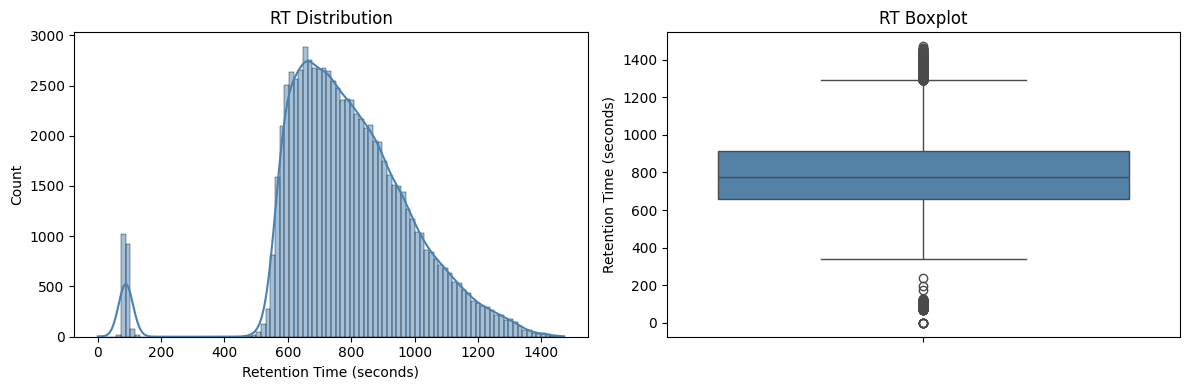

RT Stats:
count    79957.00
mean       790.11
std        206.65
min          0.30
25%        660.90
50%        773.40
75%        912.30
max       1471.70
Name: rt, dtype: float64


In [12]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.histplot(df_features['rt'], bins=100, kde=True, color='steelblue')
plt.xlabel('Retention Time (seconds)')
plt.ylabel('Count')
plt.title('RT Distribution')

plt.subplot(1, 2, 2)
sns.boxplot(y=df_features['rt'], color='steelblue')
plt.ylabel('Retention Time (seconds)')
plt.title('RT Boxplot')

plt.tight_layout()
plt.savefig('data/rt_distribution.png', dpi=150)
plt.show()

print(f"RT Stats:")
print(df_features['rt'].describe().round(2))

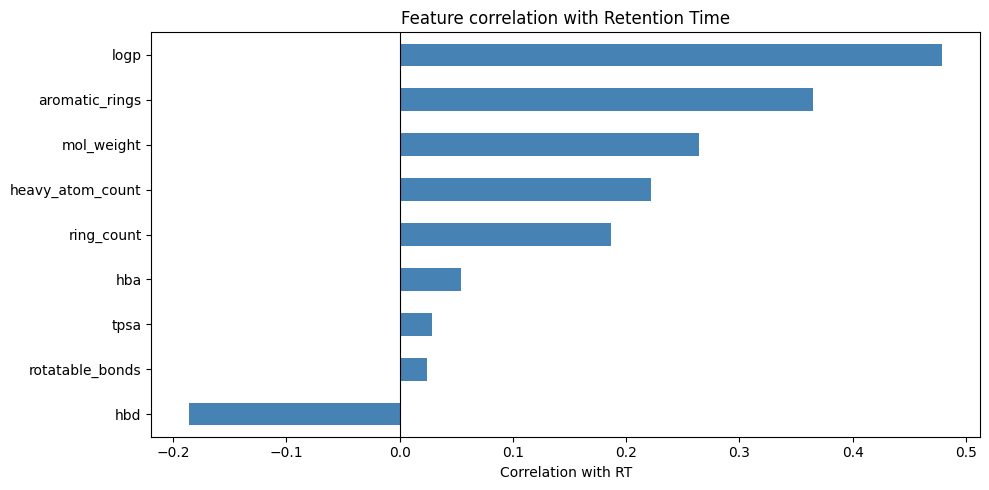


Correlation values:
hbd                -0.1860
rotatable_bonds     0.0242
tpsa                0.0284
hba                 0.0538
ring_count          0.1869
heavy_atom_count    0.2221
mol_weight          0.2640
aromatic_rings      0.3651
logp                0.4792
dtype: float64


In [13]:
FEATURES = ['mol_weight', 'logp', 'hbd', 'hba', 
            'tpsa', 'rotatable_bonds', 'heavy_atom_count',
            'ring_count', 'aromatic_rings']

plt.figure(figsize=(10, 5))
correlations = df_features[FEATURES].corrwith(df_features['rt']).sort_values()
correlations.plot(kind='barh', color='steelblue')
plt.xlabel('Correlation with RT')
plt.title('Feature correlation with Retention Time')
plt.axvline(x=0, color='black', linewidth=0.8)
plt.tight_layout()
plt.savefig('data/feature_correlation.png', dpi=150)
plt.show()

print("\nCorrelation values:")
print(correlations.round(4))

In [14]:
from rdkit import Chem
from rdkit.Chem import Descriptors, rdMolDescriptors, AllChem
from rdkit.Chem.inchi import MolFromInchi
import numpy as np
import pandas as pd

def compute_features_v2(inchi):
    try:
        mol = MolFromInchi(inchi)
        if mol is None:
            return None
        
        # Basic descriptors
        base = {
            'mol_weight':       Descriptors.MolWt(mol),
            'logp':             Descriptors.MolLogP(mol),
            'hbd':              rdMolDescriptors.CalcNumHBD(mol),
            'hba':              rdMolDescriptors.CalcNumHBA(mol),
            'tpsa':             Descriptors.TPSA(mol),
            'rotatable_bonds':  rdMolDescriptors.CalcNumRotatableBonds(mol),
            'heavy_atom_count': mol.GetNumHeavyAtoms(),
            'ring_count':       rdMolDescriptors.CalcNumRings(mol),
            'aromatic_rings':   rdMolDescriptors.CalcNumAromaticRings(mol),
        }
        
        # Morgan fingerprints (128 bits)
        fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=128)
        fp_dict = {f'fp_{i}': int(fp[i]) for i in range(128)}
        
        return {**base, **fp_dict}
    except:
        return None

print("Recomputing features with fingerprints... (~4 mins)")

features_list = []
failed = 0

for i, row in df.iterrows():
    feats = compute_features_v2(row['inchi'])
    if feats:
        feats['pubchem'] = row['pubchem']
        feats['rt']      = row['rt']
        features_list.append(feats)
    else:
        failed += 1

df_v2 = pd.DataFrame(features_list)
df_v2 = df_v2[df_v2['rt'] > 200].copy()

df_v2.to_csv('data/SMRT_features_v2.csv', index=False)
print(f"Done! Shape: {df_v2.shape}")
print(f"Failed: {failed}")

Recomputing features with fingerprints... (~4 mins)


[11:02:55] DEPRECATION WARNING: please use MorganGenerator
[11:02:55] DEPRECATION WARNING: please use MorganGenerator
[11:02:55] DEPRECATION WARNING: please use MorganGenerator
[11:02:55] DEPRECATION WARNING: please use MorganGenerator
[11:02:55] DEPRECATION WARNING: please use MorganGenerator
[11:02:55] DEPRECATION WARNING: please use MorganGenerator
[11:02:55] DEPRECATION WARNING: please use MorganGenerator
[11:02:55] DEPRECATION WARNING: please use MorganGenerator
[11:02:55] DEPRECATION WARNING: please use MorganGenerator
[11:02:55] DEPRECATION WARNING: please use MorganGenerator
[11:02:55] DEPRECATION WARNING: please use MorganGenerator
[11:02:55] DEPRECATION WARNING: please use MorganGenerator
[11:02:55] DEPRECATION WARNING: please use MorganGenerator
[11:02:55] DEPRECATION WARNING: please use MorganGenerator
[11:02:55] DEPRECATION WARNING: please use MorganGenerator
[11:02:55] DEPRECATION WARNING: please use MorganGenerator
[11:02:55] DEPRECATION WARNING: please use MorganGenerat

Done! Shape: (77901, 139)
Failed: 81
